In [1]:
import pandas as pd
import numpy as np
print(np.__version__)
import csv
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator


import os

import warnings
warnings.filterwarnings(
    "ignore",
    message="Converting to PeriodArray/Index representation will drop timezone information"
)


1.24.3


In [2]:
#for period 1
fl_path1 = 'lerwick_3145'
#fl_name = f'day-{i}-classifications.csv'
csv_files1 = [file for file in os.listdir(fl_path1) if file.endswith('.csv') ]
all_dfs1 = []
for csv_file1 in csv_files1:
    file_path1 = os.path.join(fl_path1, csv_file1)
    temp_df1 = pd.read_csv(file_path1, cache_dates=False)
    temp_df1["created_at"] = pd.to_datetime(temp_df1["created_at"])

    all_dfs1.append(temp_df1)
    
df1 = pd.concat(all_dfs1, ignore_index=True)
#print(df1)

p1_df=df1.groupby(df1["created_at"].dt.date).size().reset_index(name="count")
p1_df1 = df1.groupby(df1["created_at"].dt.to_period("M")).size().reset_index(name="count")

p1_df.to_csv('summary_outputs_period1.csv', index=True)  
print(p1_df["count"].sum())
print(df1["user_name"].nunique())

8986
819


In [3]:
#for period 2
fl_path = 'Lerwick_data_7days'
#fl_name = f'day-{i}-classifications.csv'
csv_files = [file for file in os.listdir(fl_path) if file.endswith('.csv') ]
all_dfs = []
for csv_file in csv_files:
    file_path = os.path.join(fl_path, csv_file)
    print(file_path)
    temp_df = pd.read_csv(file_path, cache_dates=False)

    temp_df["created_at"] = pd.to_datetime(temp_df["created_at"])
    #print ( temp_df["created_at"] )
    all_dfs.append(temp_df)

df = pd.concat(all_dfs, ignore_index=True)

new_df=df.groupby(df["created_at"].dt.date).size().reset_index(name="count")
new_df1 = df.groupby(df["created_at"].dt.to_period("M")).size().reset_index(name="count")
new_df.to_csv('summary_outputs.csv', index=True)  
#print(new_df)

print(new_df["count"].sum())
print(df["user_name"].nunique())


Lerwick_data_7days\day-1-classifications.csv
Lerwick_data_7days\day-2-classifications.csv
Lerwick_data_7days\day-3-classifications.csv
Lerwick_data_7days\day-4-classifications.csv
Lerwick_data_7days\day-5-classifications.csv
Lerwick_data_7days\day-6-classifications.csv
Lerwick_data_7days\day-7-classifications.csv
22184
981


In [4]:
volunteer = pd.concat([df1, df], ignore_index=True)
volunteer["created_at"] = pd.to_datetime(volunteer["created_at"])
vol_merged = pd.concat([p1_df, new_df], ignore_index=True)
vol_merged1 = pd.concat([p1_df1, new_df1], ignore_index=True)

In [5]:
#ok part
by_vol_df = volunteer.groupby("user_name").size().reset_index(name="count")#["created_at"].count()
#print(by_vol_df)


first_seen = volunteer.groupby("user_name")["created_at"].min().reset_index()
per_day = first_seen.groupby(first_seen["created_at"].dt.date).size().reset_index(name="count")
per_day["count"] = per_day["count"].astype(int)
per_month = first_seen.groupby(first_seen["created_at"].dt.to_period("M")).size()
#print(per_day)
#first_seen.groupby(pd.Grouper(key="created_at", freq="D")).size()
#first_seen.groupby(pd.Grouper(key="created_at", freq="M")).size()



# new volunteers per day
daily_new = (
    first_seen
    .groupby(pd.Grouper(key="created_at", freq="D"))
    .size()
    .reset_index(name="new_volunteers")
)

# cumulative volunteers over time
daily_new["total_volunteers"] = daily_new["new_volunteers"].cumsum()


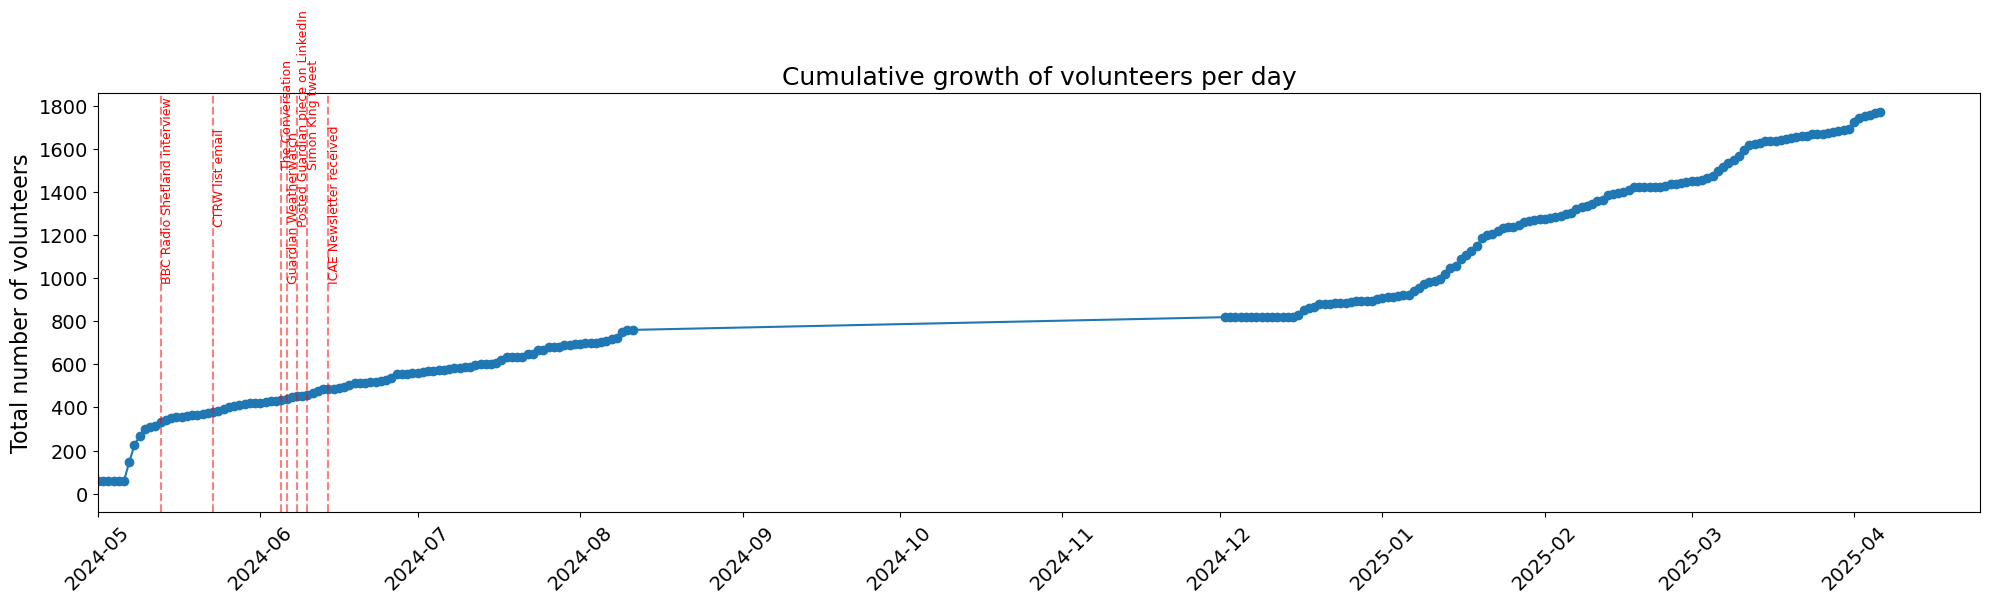

In [6]:
filtered = daily_new[
    ~(
        (daily_new["created_at"] >= "2024-08-12") &
        (daily_new["created_at"] <= "2024-12-01")
    )
]


fig, ax = plt.subplots(figsize=(20, 6))

#ax.plot(daily_new["created_at"], daily_new["total_volunteers"], marker="o")
#ax.plot(daily_new1["created_at"], daily_new1["total_volunteers"], marker="o")

ax.plot(
    filtered["created_at"],
    filtered["total_volunteers"],
    marker="o"
)

events = {
    "2024-05-13": "BBC Radio Shetland interview",
    "2024-05-23": "CTRW list email",
    "2024-06-05": "The Conversation",
    "2024-06-06": "Guardian Weatherwatch",
    "2024-06-08": "Posted Guardian piece on LinkedIn",
    "2024-06-10": "Simon King tweet",
    "2024-06-14": "ICAE Newsletter received",

}

ymax = daily_new["total_volunteers"].max()

heights = [0.55, 0.70, 0.85]

for i, (date, label) in enumerate(events.items()):

    event_date = pd.Timestamp(date)

    ax.axvline(
        event_date,
        color="red",
        linestyle="--",
        alpha=0.5
    )

    ax.text(
        event_date,
        ymax * heights[i % len(heights)],
        label,
        rotation=90,
        color="red",
        fontsize=9,
        va="bottom"
    )
    
ax.set_title("Cumulative growth of volunteers per day", fontsize=18)
#ax.set_xlabel("Date", fontsize=16)
ax.set_ylabel("Total number of volunteers", fontsize=16)
ax.set_xlim(pd.Timestamp('2024-05-01'),
            pd.Timestamp('2025-04-25'))
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)

from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

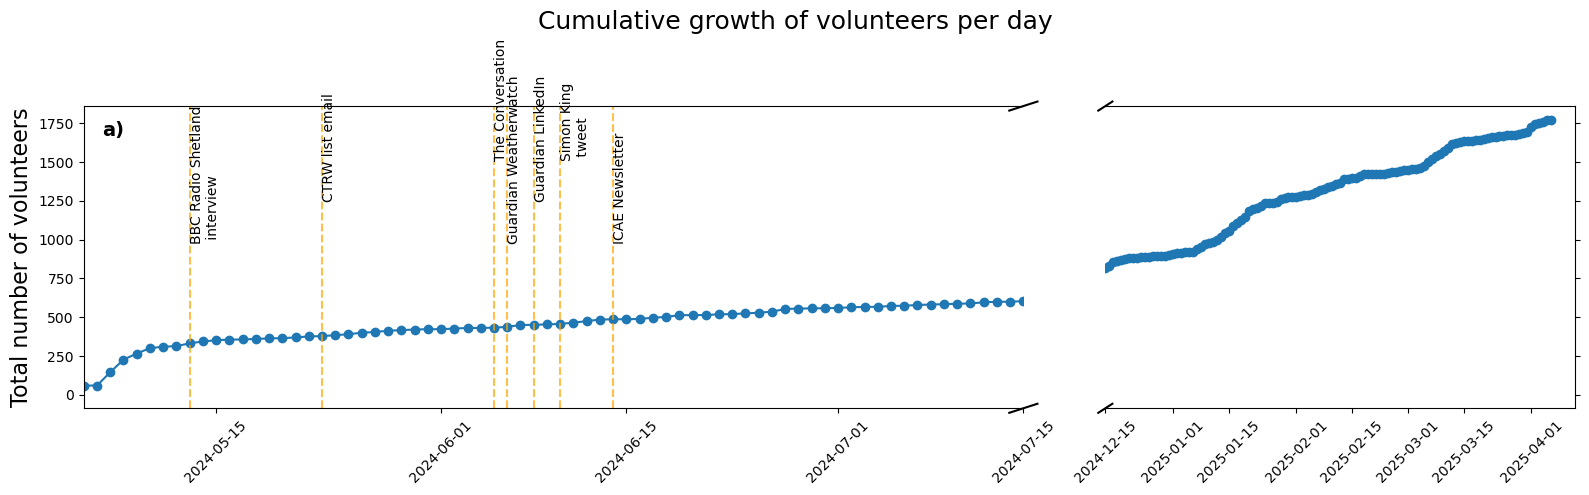

In [14]:
fig, (ax1, ax3) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(16, 5),
    gridspec_kw={'width_ratios': [2, 1]}
)

# split data
left = daily_new[daily_new["created_at"] < "2024-08-12"]
right = daily_new[daily_new["created_at"] > "2024-12-01"]

# plot both sides
ax1.plot(left["created_at"], left["total_volunteers"], marker="o")
ax3.plot(right["created_at"], right["total_volunteers"], marker="o")

events = {
    "2024-05-13": "BBC Radio Shetland \n interview",
    "2024-05-23": "CTRW list email",
    "2024-06-05": "The Conversation",
    "2024-06-06": "Guardian Weatherwatch",
    "2024-06-08": "Guardian LinkedIn",
    "2024-06-10": "Simon King \n tweet",
    "2024-06-14": "ICAE Newsletter",
    "2024-09-10": "Zooniverse highlight"
}

ymax = daily_new["total_volunteers"].max()
heights = [0.55, 0.70, 0.85]

for i, (date, label) in enumerate(events.items()):
    event_date = pd.Timestamp(date)

    if event_date < pd.Timestamp("2024-08-12"):
        ax = ax1
    elif event_date > pd.Timestamp("2024-12-01"):
        ax = ax3
    else:
        continue   # skipped because it is inside compressed gap

    ax.axvline(event_date, color="orange", linestyle="--", alpha=0.7)

    ax.text(
        event_date,
        ymax * heights[i % len(heights)],
        label,
        rotation=90,
        color="black",
        fontsize=10,
        va="bottom"
    )


# limits
ax1.set_xlim(pd.Timestamp("2024-05-05"),
             pd.Timestamp("2024-07-15"))

ax3.set_xlim(pd.Timestamp("2024-12-15"),
             pd.Timestamp("2025-04-12"))

# hide connecting spines
ax1.spines['right'].set_visible(False)
ax3.spines['left'].set_visible(False)

ax1.yaxis.tick_left()
ax3.yaxis.tick_right()

ax1.text(
        0.02, 0.95,
        'a)',
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )



# diagonal break marks
d = .015

kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((1-d, 1+d), (-d, +d), **kwargs)
ax1.plot((1-d, 1+d), (1-d, 1+d), **kwargs)

kwargs.update(transform=ax3.transAxes)
ax3.plot((-d, +d), (-d, +d), **kwargs)
ax3.plot((-d, +d), (1-d, 1+d), **kwargs)

# labels
fig.suptitle("Cumulative growth of volunteers per day", fontsize=18)
ax1.set_ylabel("Total number of volunteers", fontsize=16)

plt.setp(ax1.get_xticklabels(), rotation=45)

plt.setp(ax3.get_xticklabels(), rotation=45)
plt.savefig('figures/Figure1A_appendix.png', dpi=300)
plt.tight_layout()
plt.show()

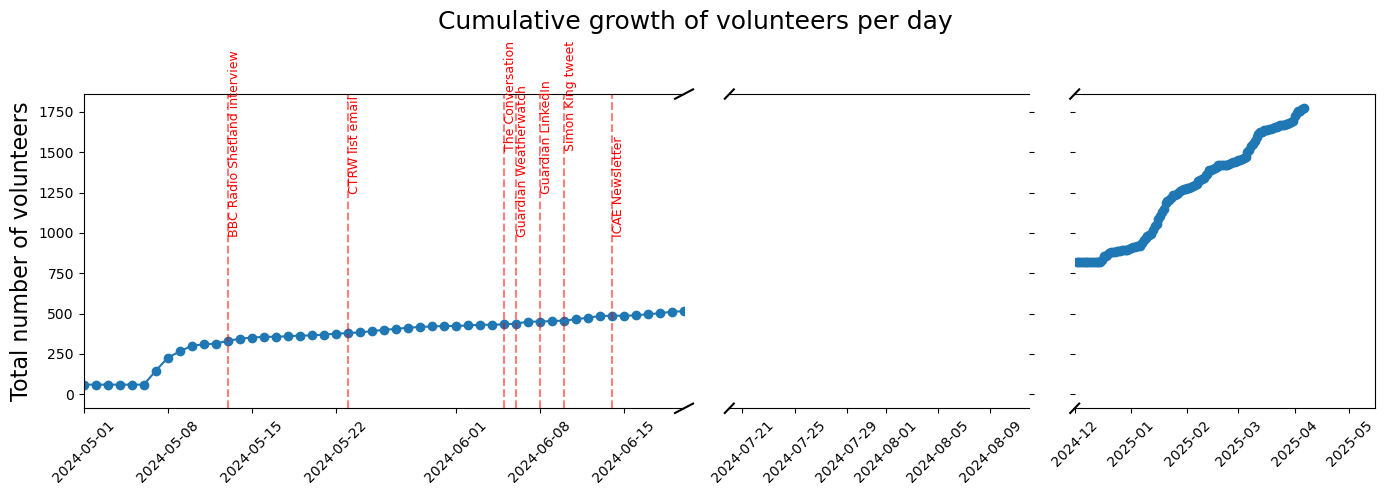

In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3,
    sharey=True,
    figsize=(14, 5),
    gridspec_kw={'width_ratios': [2, 1,1]}
)

# split data
left = daily_new[daily_new["created_at"] < "2024-08-12"]
center = daily_new[
    (daily_new["created_at"] > "2024-07-20") &
    (daily_new["created_at"] < "2024-12-01")
]
right = daily_new[daily_new["created_at"] > "2024-12-01"]

# plot both sides
ax1.plot(left["created_at"], left["total_volunteers"], marker="o")
ax2.plot(right["created_at"], right["total_volunteers"], marker="o")
ax3.plot(right["created_at"], right["total_volunteers"], marker="o")

events = {
    "2024-05-13": "BBC Radio Shetland interview",
    "2024-05-23": "CTRW list email",
    "2024-06-05": "The Conversation",
    "2024-06-06": "Guardian Weatherwatch",
    "2024-06-08": "Guardian LinkedIn",
    "2024-06-10": "Simon King tweet",
    "2024-06-14": "ICAE Newsletter"
    #"2024-09-10": "Zooniverse highlight"
}

ymax = daily_new["total_volunteers"].max()
heights = [0.55, 0.70, 0.85]

for i, (date, label) in enumerate(events.items()):
    event_date = pd.Timestamp(date)

    if event_date < pd.Timestamp("2024-08-12"):
        ax = ax1
    elif  pd.Timestamp("2024-06-15") < event_date < pd.Timestamp("2024-12-01") :
        ax = ax2
    elif event_date > pd.Timestamp("2024-12-01"):
        ax = ax3
    else:
        continue   # skipped because it is inside compressed gap

    ax.axvline(event_date, color="red", linestyle="--", alpha=0.5)

    ax.text(
        event_date,
        ymax * heights[i % len(heights)],
        label,
        rotation=90,
        color="red",
        fontsize=9,
        va="bottom"
    )


# limits
ax1.set_xlim(pd.Timestamp("2024-05-01"),
             pd.Timestamp("2024-06-20"))

ax2.set_xlim(pd.Timestamp("2024-07-20"),
             pd.Timestamp("2024-08-12"))#2024-08-12
ax3.set_xlim(pd.Timestamp("2024-12-01"),
             pd.Timestamp("2025-05-15"))

# hide connecting spines
ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax3.spines['left'].set_visible(False)

ax1.yaxis.tick_left()
ax2.yaxis.tick_right()

# diagonal break marks
d = .015

kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((1-d, 1+d), (-d, +d), **kwargs)
ax1.plot((1-d, 1+d), (1-d, 1+d), **kwargs)

kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (-d, +d), **kwargs)
ax2.plot((-d, +d), (1-d, 1+d), **kwargs)

kwargs.update(transform=ax3.transAxes)
ax3.plot((-d, +d), (-d, +d), **kwargs)
ax3.plot((-d, +d), (1-d, 1+d), **kwargs)

# labels
fig.suptitle("Cumulative growth of volunteers per day", fontsize=18)
ax1.set_ylabel("Total number of volunteers", fontsize=16)

plt.setp(ax1.get_xticklabels(), rotation=45)
plt.setp(ax2.get_xticklabels(), rotation=45)
plt.setp(ax3.get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

In [9]:
vol_merged["created_at"] = pd.to_datetime(vol_merged["created_at"])

daily_counts = (
    vol_merged
    .groupby("created_at")["count"]
    .sum()
    .reset_index()
    .sort_values("created_at")
)

daily_counts["total"] = daily_counts["count"].cumsum()

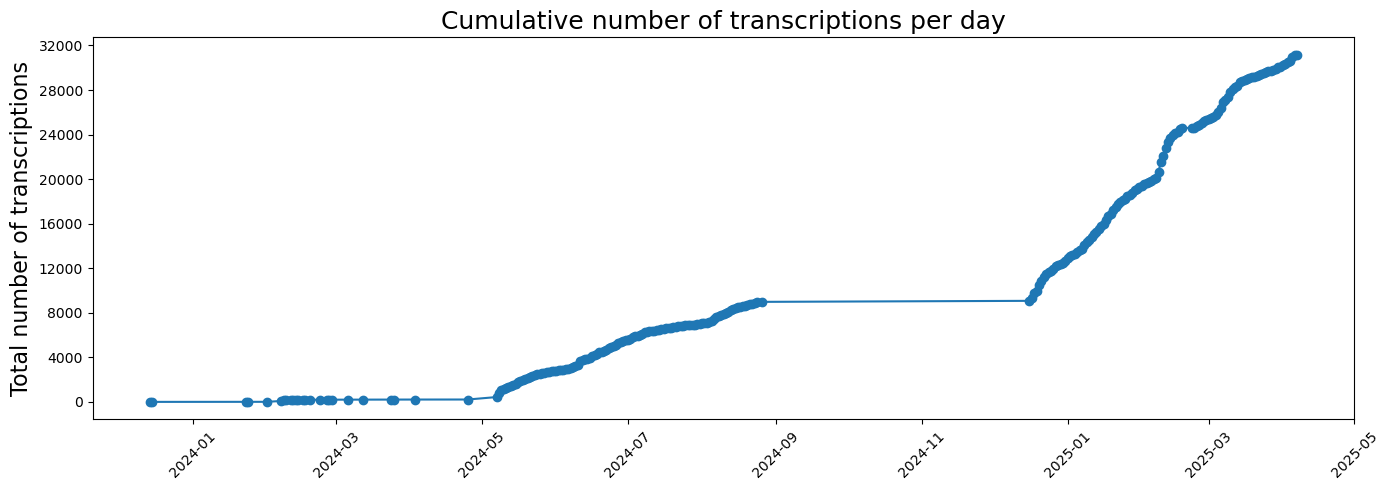

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(daily_counts["created_at"], daily_counts["total"], marker="o")

ax.set_title("Cumulative number of transcriptions per day", fontsize=18)
ax.set_ylabel("Total number of transcriptions", fontsize=16)

from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

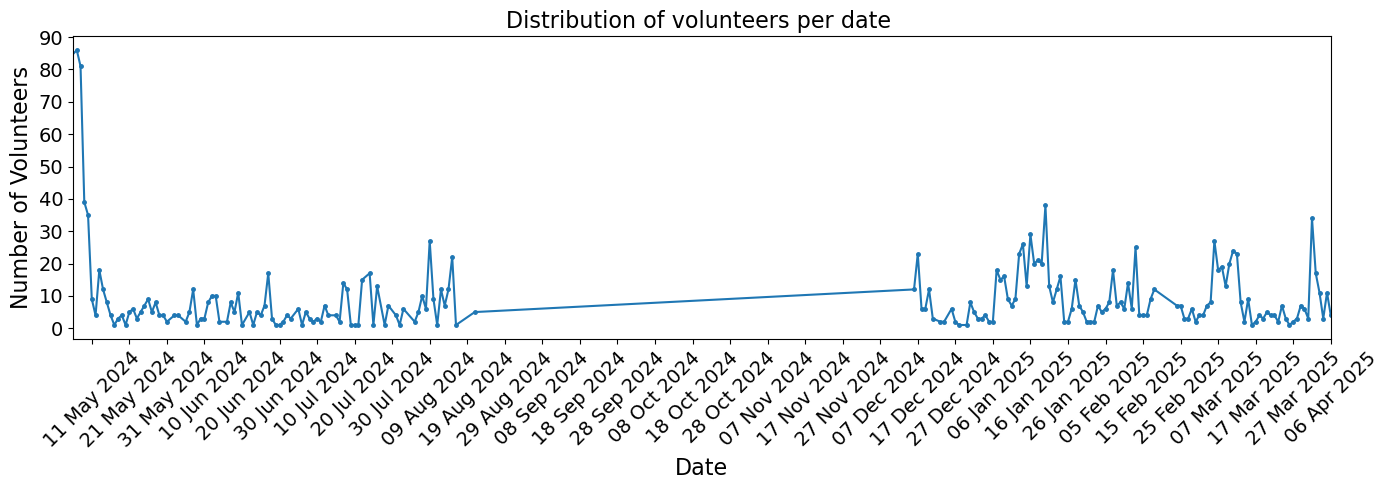

In [11]:
#per months
plt.figure(figsize=(14,5))
plt.plot(per_day['created_at'], per_day['count'], linestyle='-',
             marker='.',
             markersize=5)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=10))
#ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))#(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax.set_xlim(pd.Timestamp('2024-05-06'),
           pd.Timestamp('2025-04-06'))

ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel('Date', fontsize=16)
plt.ylabel('Number of Volunteers', fontsize=16)
plt.xticks(rotation=45)
plt.title('Distribution of volunteers per date ', fontsize=16)
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
#plt.savefig(fig_out+ 'monthly_count_2.png', dpi=300)#name_+
plt.show()

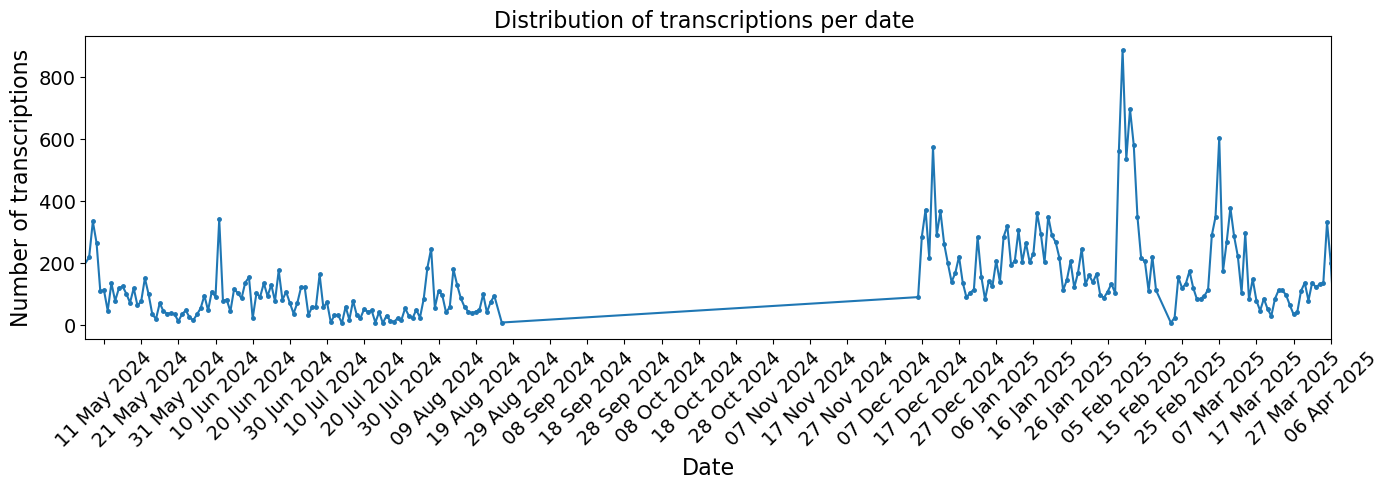

In [12]:
#per months
plt.figure(figsize=(14,5))
plt.plot(vol_merged['created_at'], vol_merged['count'], linestyle='-',
             marker='.',
             markersize=5)

# split data
left = daily_new[daily_new["created_at"] < "2024-08-12"]
right = daily_new[daily_new["created_at"] > "2024-12-01"]

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.DayLocator(interval=10))
#ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))#(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))

ax.set_xlim(pd.Timestamp('2024-05-06'),
           pd.Timestamp('2025-04-06'))

ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel('Date', fontsize=16)
plt.ylabel('Number of transcriptions', fontsize=16)
plt.xticks(rotation=45)
plt.title('Distribution of transcriptions per date ', fontsize=16)
plt.tight_layout()#rect=[0.05, 0.05, 1, 1])
#plt.savefig(fig_out+ 'monthly_count_2.png', dpi=300)#name_+
plt.show()

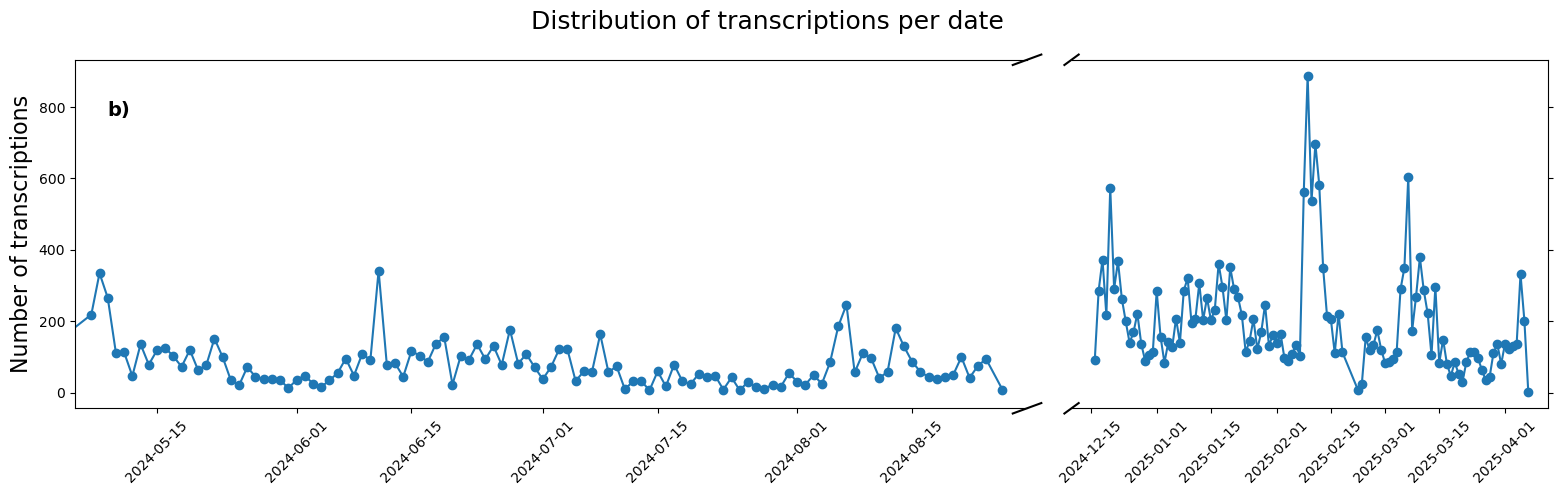

In [15]:
fig, (ax1, ax3) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(16, 5),
    gridspec_kw={'width_ratios': [2, 1]}
)
# split data
left = vol_merged[vol_merged["created_at"] < "2024-08-29"]
right = vol_merged[vol_merged["created_at"] > "2024-11-27"]

# plot both sides
ax1.plot(left["created_at"], left["count"], marker="o")
ax3.plot(right["created_at"], right["count"], marker="o")



#per months
#plt.figure(figsize=(14,5))
#plt.plot(vol_merged['created_at'], vol_merged['count'], linestyle='-',
            # marker='.',
           #  markersize=5)





# limits
ax1.set_xlim(pd.Timestamp("2024-05-05"),
             pd.Timestamp("2024-08-29"))

ax3.set_xlim(pd.Timestamp("2024-12-10"),
             pd.Timestamp("2025-04-12"))

ax1.text(
        0.02, 1,
        'b)',
        transform=ax.transAxes,
        fontsize=14,
        fontweight='bold',
        va='top'
    )

# hide connecting spines
ax1.spines['right'].set_visible(False)
ax3.spines['left'].set_visible(False)

ax1.yaxis.tick_left()
ax3.yaxis.tick_right()

# diagonal break marks
d = .015

kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
ax1.plot((1-d, 1+d), (-d, +d), **kwargs)
ax1.plot((1-d, 1+d), (1-d, 1+d), **kwargs)

kwargs.update(transform=ax3.transAxes)
ax3.plot((-d, +d), (-d, +d), **kwargs)
ax3.plot((-d, +d), (1-d, 1+d), **kwargs)

# labels
fig.suptitle("Distribution of transcriptions per date", fontsize=18)
ax1.set_ylabel("Number of transcriptions", fontsize=16)

plt.setp(ax1.get_xticklabels(), rotation=45)

plt.setp(ax3.get_xticklabels(), rotation=45)

plt.tight_layout()
plt.savefig('figures/Figure1Ab_appendix.png', dpi=300)
plt.show()

